<a href="https://colab.research.google.com/github/sabrina-cortes/Metodos-Numericos-FIS1344-TAREAS/blob/main/tarea_7_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 7.4 — Cuadratura adaptativa

Se pide calcular la integral

$$
I=\int_0^3
\frac{1}{\sqrt{2\pi}}
e^{-x^2/2}\,dx
$$

utilizando el método de cuadratura adaptativa.

Se calculará la integral para distintas tolerancias y se comparará con el valor exacto. Luego se graficará el error obtenido en función de la tolerancia.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

Definimos la función gaussiana estándar:

$$
f(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2}.
$$

In [8]:
def f(x):
    return (1/np.sqrt(2*np.pi))*np.exp(-x**2/2)

Usaremos el método de cuadratura adaptativa.

El método compara una aproximación de Simpson en un intervalo completo con la suma de las aproximaciones obtenidas al dividir dicho intervalo en dos.

Si la diferencia es suficientemente pequeña, se acepta la aproximación. En caso contrario, el intervalo se vuelve a dividir.

In [9]:
class MaxIterations(Exception):
    pass

def adaptive(f, a, b, tol, N=100_000):

    approx = 0
    i = 0

    toli = [10*tol]
    ai = [a]
    hi = [(b - a)/2]

    fai = [f(a)]
    fbi = [f(b)]
    fci = [f(a + hi[i])]

    S0i = [hi[i]*(fai[i] + 4*fci[i] + fbi[i])/3]
    Li = [1]

    while i >= 0:

        fd = f(ai[i] + hi[i]/2)
        fe = f(ai[i] + 3*hi[i]/2)

        S1 = hi[i]*(fai[i] + 4*fd + fci[i])/6
        S2 = hi[i]*(fci[i] + 4*fe + fbi[i])/6

        ai_prec = ai[i]
        hi_prec = hi[i]
        fai_prec = fai[i]
        fbi_prec = fbi[i]
        fci_prec = fci[i]
        toli_prec = toli[i]
        S0i_prec = S0i[i]
        Li_prec = Li[i]

        i -= 1

        if abs(S1 + S2 - S0i_prec) < toli_prec:
            approx += S1 + S2

        else:

            if Li_prec >= N:
                raise MaxIterations("Alcanzado máximo número de iteraciones.")

            # Intervalo derecho
            i += 1

            if i >= len(ai):

                ai.append(ai_prec + hi_prec)
                fai.append(fci_prec)
                fci.append(fe)
                fbi.append(fbi_prec)

                hi.append(hi_prec/2)
                toli.append(toli_prec/2)
                S0i.append(S2)
                Li.append(Li_prec + 1)

            else:

                ai[i] = ai_prec + hi_prec
                fai[i] = fci_prec
                fci[i] = fe
                fbi[i] = fbi_prec

                hi[i] = hi_prec/2
                toli[i] = toli_prec/2
                S0i[i] = S2
                Li[i] = Li_prec + 1

            # Intervalo izquierdo
            i += 1

            if i >= len(ai):

                ai.append(ai_prec)
                fai.append(fai_prec)
                fci.append(fd)
                fbi.append(fci_prec)

                hi.append(hi[i-1])
                toli.append(toli[i-1])
                S0i.append(S1)
                Li.append(Li[i-1])

            else:

                ai[i] = ai_prec
                fai[i] = fai_prec
                fci[i] = fd
                fbi[i] = fci_prec

                hi[i] = hi[i-1]
                toli[i] = toli[i-1]
                S0i[i] = S1
                Li[i] = Li[i-1]

    return approx

El valor exacto puede obtenerse usando la función de error:

$$
\int_0^x
\frac{1}{\sqrt{2\pi}}
e^{-t^2/2}\,dt
=
\frac{1}{2}
\operatorname{erf}
\left(
\frac{x}{\sqrt{2}}
\right).
$$

Para $x=3$:

$$
I_{\text{exacto}}
=
\frac{1}{2}
\operatorname{erf}
\left(
\frac{3}{\sqrt{2}}
\right).
$$

In [10]:
exacto = 0.5*erf(3/np.sqrt(2))

print("Valor exacto =", exacto)

Valor exacto = 0.4986501019683699


In [11]:
tolerancias = 10.0**(-np.arange(2, 11))

aproximaciones = []
errores = []

for tol in tolerancias:

    aprox = adaptive(f, 0, 3, tol)

    error = abs(aprox - exacto)

    aproximaciones.append(aprox)
    errores.append(error)

    print("tol =", tol,
          "aproximación =", aprox,
          "error =", error)

tol = 0.01 aproximación = 0.49847941402676044 error = 0.00017068794160945977
tol = 0.001 aproximación = 0.49864153455025817 error = 8.567418111726788e-06
tol = 0.0001 aproximación = 0.49864153455025817 error = 8.567418111726788e-06
tol = 1e-05 aproximación = 0.49866537649955905 error = 1.527453118915778e-05
tol = 1e-06 aproximación = 0.49865010045102487 error = 1.5173450274019729e-09
tol = 1e-07 aproximación = 0.4986500897898311 error = 1.2178538788543136e-08
tol = 1e-08 aproximación = 0.4986501018528574 error = 1.1551248846330964e-10
tol = 1e-09 aproximación = 0.4986501020060595 error = 3.768962919536989e-11
tol = 1e-10 aproximación = 0.49865010197181464 error = 3.4447444896557045e-12


Para cada tolerancia se calcula el error absoluto:

$$
E=
|I_{\text{aprox}}-I_{\text{exacto}}|.
$$

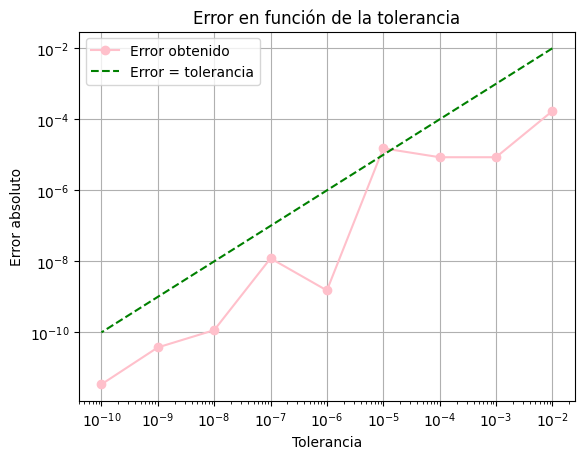

In [12]:
plt.loglog(tolerancias, errores, 'o-', color= 'pink' ,label="Error obtenido")
plt.loglog(tolerancias, tolerancias, '--', color= 'green' ,label="Error = tolerancia")

plt.xlabel("Tolerancia")
plt.ylabel("Error absoluto")
plt.title("Error en función de la tolerancia")

plt.grid()
plt.legend()
plt.show()

## Análisis

Se observa que al disminuir la tolerancia también disminuye el error de la aproximación.

Esto es lo esperado, ya que una tolerancia menor obliga al método adaptativo a dividir más los intervalos donde la aproximación de Simpson todavía no alcanza la precisión requerida.

Sin embargo, el error real no tiene por qué coincidir exactamente con la tolerancia, ya que el algoritmo utiliza una estimación del error basada en la diferencia entre dos aproximaciones de Simpson.

Para tolerancias suficientemente pequeñas, la disminución del error puede dejar de ser proporcional a la tolerancia debido a los errores de redondeo propios de la representación en punto flotante.

La cuadratura adaptativa permitió aproximar la integral de la distribución gaussiana estándar en el intervalo $[0,3]$ con distintas tolerancias.

Al comparar con el valor exacto obtenido mediante la función de error, se observa que la precisión mejora al disminuir la tolerancia.

Este comportamiento es consistente con lo esperado para un método adaptativo, ya que el algoritmo subdivide el intervalo de integración hasta alcanzar localmente la precisión requerida.

## Nota: 7.0

Base: 1/1; funcionamiento: 4/4; comentarios: 1/1; claridad: 1/1.
